# 03 · Caso 1 — otimização: produção máxima e lucro máximo

Reprodução da Seção 6.1 do artigo: Figs. 13–16 e Tabela 13. O problema de otimização
(Eq. 24) acopla o simulador de rede (que especifica vazões) ao modelo de reservatório
$Q_L = PI\,(P_{res} - P_{downhole})$ por meio de uma restrição de igualdade, resolvido com
programação quadrática sequencial (SLSQP do SciPy, equivalente ao `fmincon` usado no artigo).

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, display

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
if str(ROOT / "src") not in sys.path:
    sys.path.insert(0, str(ROOT / "src"))
REF = ROOT / "data" / "reference"
FIG = ROOT / "docs" / "paper" / "figures"
pd.set_option("display.precision", 4)
pd.set_option("display.width", 140)
plt.rcParams.update({"figure.dpi": 100, "figure.figsize": (7, 5), "axes.grid": True, "grid.alpha": 0.3})

In [2]:
import json, time
from gaslift import case1_single_well, SimulationOptions, ModelOptions, IntegrationOptions
from gaslift.optimization import GasLiftProblem, Objective, Reservoir
from gaslift.economics import CostModel
from gaslift.plotting import plot_rate_contours
from gaslift.sweeps import sweep_rates

matlab = json.load(open(REF / "matlab_optimization_results.json"))

def optimise(objective, reservoir, cost=None, x0=(10.0, 2.0)):
    case = case1_single_well()
    prob = GasLiftProblem(case, [reservoir], objective, cost=cost or CostModel(), oil_bounds=(5.0, 20.0), gas_bounds=(1.0, 4.0))
    t0 = time.perf_counter()
    res = prob.solve(prob.initial_vector(*x0))
    res.elapsed = time.perf_counter() - t0
    return res

## 6.1.1 · Produção máxima para diferentes pressões de fundo (Figs. 13 e 14)

Índice de produtividade infinito: a pressão de fundo é igual à pressão do reservatório.
A superfície da produção é muito plana na direção da vazão de gás perto do ótimo, de modo que
otimizadores diferentes podem parar em vazões de gás ligeiramente distintas com a mesma
produção (compare as colunas Python e MATLAB; a 260 bar o SLSQP encontra produção um pouco
maior que a publicada).

In [3]:
pressures = [180, 200, 220, 240, 260]
rows = []
for p in pressures:
    res = optimise(Objective.MAX_PRODUCTION, Reservoir(p, np.inf))
    ref = matlab[f"case1_maxprod_piinf_{p}bar"]
    rows.append({"P_well (bar)": p, "oil (kg/s)": res.oil_rates[0], "gas (kg/s)": res.gas_rates[0],
                 "oil MATLAB": ref["xopt"][0], "gas MATLAB": ref["xopt"][1],
                 "evaluations": res.n_evaluations, "time (s)": res.elapsed})
fig13 = pd.DataFrame(rows).set_index("P_well (bar)")
fig13

,oil (kg/s),gas (kg/s),oil MATLAB,gas MATLAB,evaluations,time (s)
P_well (bar),,,,,,
180,6.1093,1.8604,6.1093,1.8605,28,4.1218
200,8.3135,1.8412,8.3133,1.8421,22,2.9948
220,10.8630,1.7693,10.8630,1.7718,24,3.1811
240,13.7246,1.6542,13.7246,1.6542,24,3.4762
260,16.3180,1.7095,16.2843,1.6047,104,9.2709


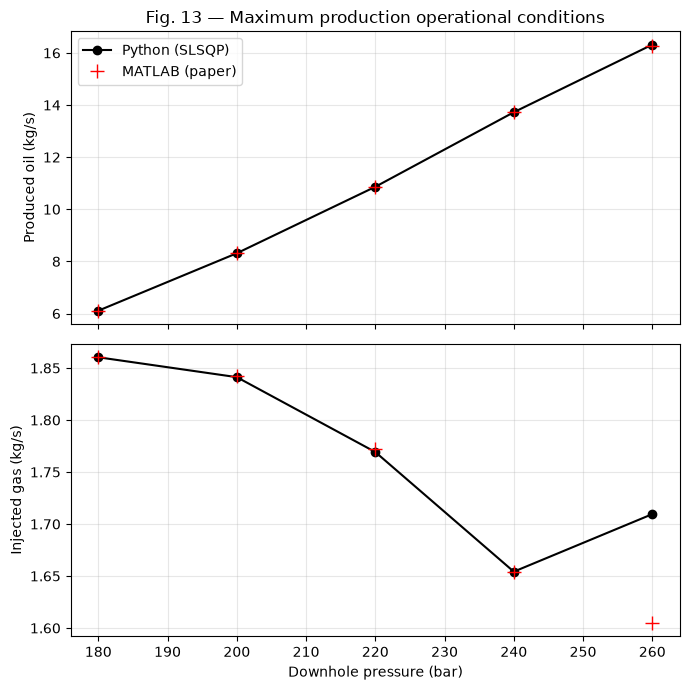

In [4]:
fig, axes = plt.subplots(2, 1, figsize=(7, 7), sharex=True)
axes[0].plot(fig13.index, fig13["oil (kg/s)"], "ko-", label="Python (SLSQP)"); axes[0].plot(fig13.index, fig13["oil MATLAB"], "r+", ms=10, label="MATLAB (paper)")
axes[0].set_ylabel("Produced oil (kg/s)"); axes[0].legend(); axes[0].set_title("Fig. 13 — Maximum production operational conditions")
axes[1].plot(fig13.index, fig13["gas (kg/s)"], "ko-"); axes[1].plot(fig13.index, fig13["gas MATLAB"], "r+", ms=10)
axes[1].set_ylabel("Injected gas (kg/s)"); axes[1].set_xlabel("Downhole pressure (bar)")
plt.tight_layout()

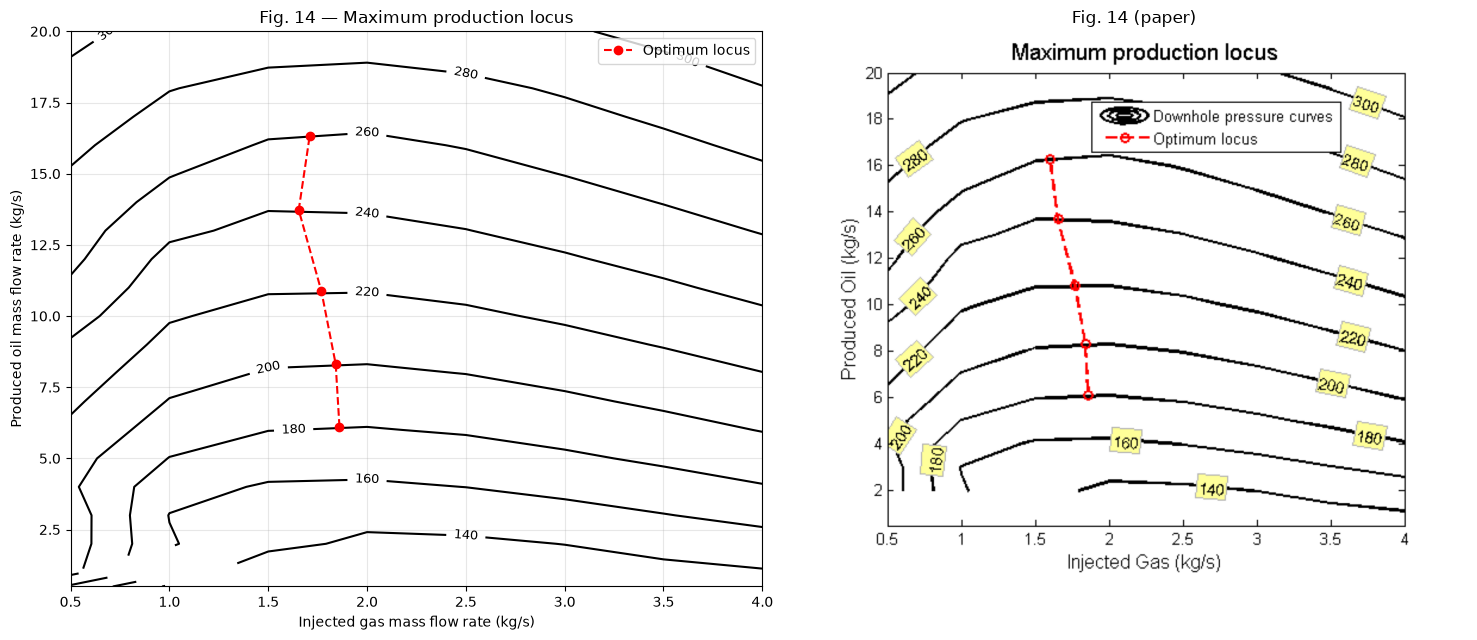

In [5]:
q_gas = np.arange(0.5, 4.01, 0.5)
q_oil = np.concatenate([[0.5], np.arange(1.0, 20.01, 1.0)])
opts = SimulationOptions(model=ModelOptions(integration=IntegrationOptions(rtol=1e-3)), compute_profiles=False)
sweep = sweep_rates(case1_single_well(), q_gas, q_oil, opts)
fig, axes = plt.subplots(1, 2, figsize=(15, 6.5))
plot_rate_contours(sweep.q_gas, sweep.q_oil, sweep.downhole(0), axes[0], np.arange(140, 320, 20), title="Fig. 14 — Maximum production locus")
axes[0].plot(fig13["gas (kg/s)"], fig13["oil (kg/s)"], "ro--", label="Optimum locus"); axes[0].legend(loc="upper right")
axes[1].imshow(plt.imread(FIG / "FIG_14.png")); axes[1].axis("off"); axes[1].set_title("Fig. 14 (paper)")
plt.tight_layout()

## 6.1.2 · Produção máxima para diferentes índices de produtividade (Fig. 15)

In [6]:
pis = [0.5, 1.0, 2.0, 5.0, 10.0]
rows = []
for pi in pis:
    res = optimise(Objective.MAX_PRODUCTION, Reservoir(220.0, pi))
    ref = matlab[f"case1_maxprod_pi{pi:g}_220bar"]
    rows.append({"PI ((kg/s)/bar)": pi, "oil (kg/s)": res.oil_rates[0], "gas (kg/s)": res.gas_rates[0],
                 "P_downhole (bar)": res.economics.downhole_pressure[0],
                 "oil MATLAB": ref["xopt"][0], "gas MATLAB": ref["xopt"][1], "P_downhole MATLAB": ref["p_downhole_bar"],
                 "time (s)": res.elapsed})
fig15 = pd.DataFrame(rows).set_index("PI ((kg/s)/bar)")
fig15

,oil (kg/s),gas (kg/s),P_downhole (bar),oil MATLAB,gas MATLAB,P_downhole MATLAB,time (s)
PI ((kg/s)/bar),,,,,,,
0.5,8.6403,1.8355,202.7196,8.6402,1.8355,202.7195,3.1549
1.0,9.5980,1.8119,210.4025,9.5979,1.8118,210.4021,3.0754
2.0,10.1827,1.7946,214.9095,10.1826,1.7944,214.9087,3.4799
5.0,10.5778,1.7803,217.8850,10.5778,1.7815,217.8844,3.2382
10.0,10.7181,1.7752,218.9286,10.7180,1.7768,218.9282,3.7210


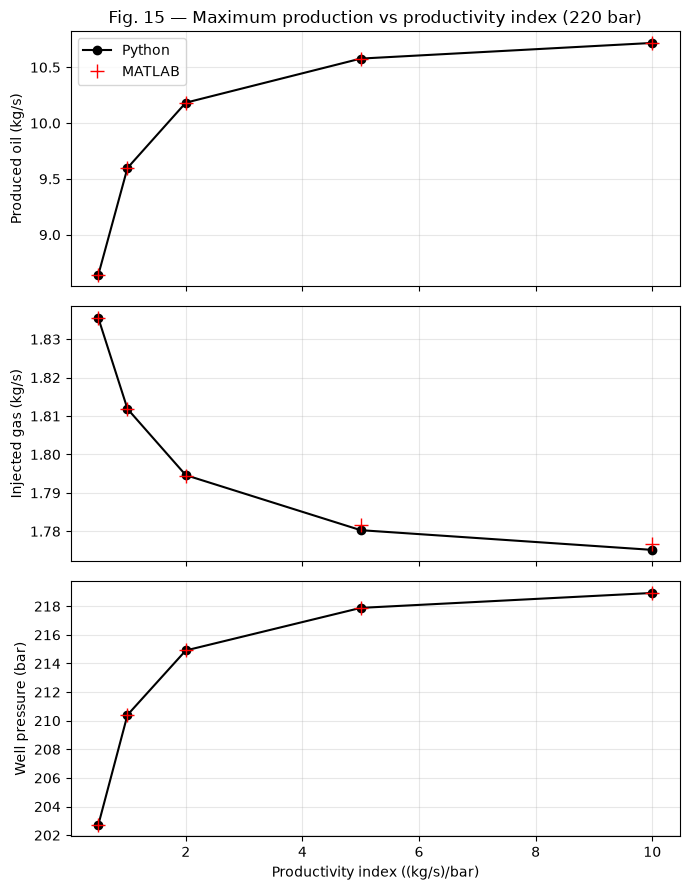

In [7]:
fig, axes = plt.subplots(3, 1, figsize=(7, 9), sharex=True)
for ax, col, ref, lab in zip(axes, ["oil (kg/s)", "gas (kg/s)", "P_downhole (bar)"], ["oil MATLAB", "gas MATLAB", "P_downhole MATLAB"],
                             ["Produced oil (kg/s)", "Injected gas (kg/s)", "Well pressure (bar)"]):
    ax.plot(fig15.index, fig15[col], "ko-", label="Python"); ax.plot(fig15.index, fig15[ref], "r+", ms=10, label="MATLAB"); ax.set_ylabel(lab)
axes[0].legend(); axes[0].set_title("Fig. 15 — Maximum production vs productivity index (220 bar)"); axes[-1].set_xlabel("Productivity index ((kg/s)/bar)")
plt.tight_layout()

## 6.1.3 · Lucro máximo (Tabela 13 e Fig. 16)

Função objetivo $\Omega_2 = R - AGC$: receita do óleo menos custo do gás combustível da
turbina do compressor (Eqs. 26, 31, 34 e 35). Os cenários variam o preço do óleo com o preço
do gás fixo em 0,1886 USD/Nm³; o cenário "Max" corresponde à produção máxima (custo nulo).

In [8]:
scenarios = [("1", 51.15 / 4, Objective.MAX_PROFIT), ("2", 51.15 / 2, Objective.MAX_PROFIT), ("3", 51.15, Objective.MAX_PROFIT), ("Max", 51.15, Objective.MAX_PRODUCTION)]
keys = {"1": "case1_maxprofit_oil12.79", "2": "case1_maxprofit_oil25.58", "3": "case1_maxprofit_oil51.15", "Max": "case1_maxprod_pi1_220bar"}
rows = {}
for name, oil_price, obj in scenarios:
    res = optimise(obj, Reservoir(220.0, 1.0), CostModel(oil_price=oil_price))
    ec = res.economics
    gas_price = 0.0 if obj is Objective.MAX_PRODUCTION else ec.fuel_gas_cost / max(ec.fuel_gas_volume, 1e-12)
    ref = matlab[keys[name]]
    rows[name] = {"Cost ratio ×10³ ((USD/Nm³)/(USD/bbl))": 1e3 * gas_price / oil_price, "Fuel gas cost (USD/Nm³)": gas_price,
                  "Oil price (USD/bbl)": oil_price, "Produced oil (kg/s)": ec.oil_rate[0], "Injected gas (kg/s)": ec.gas_rate[0],
                  "Downhole pressure (bar)": ec.downhole_pressure[0], "Compressor power (kW)": ec.compressor_power,
                  "Discharge pressure PG (bar)": ec.discharge_pressure, "Profit (10⁶ USD/yr)": ec.profit,
                  "Profit MATLAB": -ref["fob"], "Injected gas MATLAB": ref["xopt"][1]}
table13 = pd.DataFrame(rows)
table13

,1,2,3,Max
Cost ratio ×10³ ((USD/Nm³)/(USD/bbl)),14.7474,7.3737,3.6868,0.0000
Fuel gas cost (USD/Nm³),0.1886,0.1886,0.1886,0.0000
Oil price (USD/bbl),12.7875,25.5750,51.1500,51.1500
Produced oil (kg/s),9.5710,9.5907,9.5961,9.5980
Injected gas (kg/s),1.6583,1.7304,1.7697,1.8119
Downhole pressure (bar),210.4291,210.4099,210.4045,210.4025
Compressor power (kW),1002.6255,1051.8648,1078.9370,1108.1221
Discharge pressure PG (bar),269.1781,274.0392,276.7447,279.6852
Profit (10⁶ USD/yr),26.9630,55.5625,112.8224,114.5644
Profit MATLAB,26.9630,55.5621,112.8216,114.5638


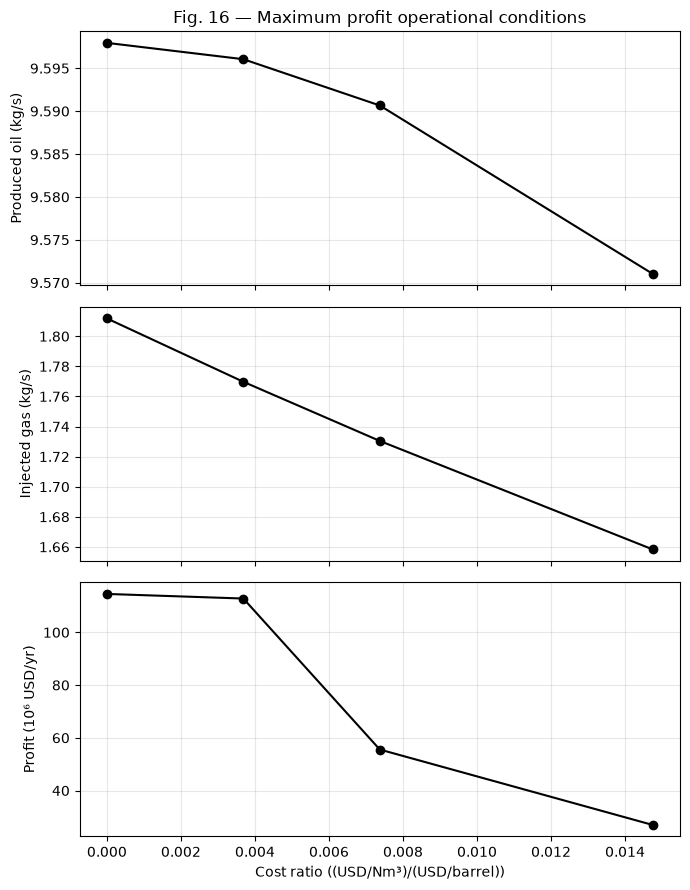

In [9]:
ratio = table13.loc["Cost ratio ×10³ ((USD/Nm³)/(USD/bbl))"] / 1e3
fig, axes = plt.subplots(3, 1, figsize=(7, 9), sharex=True)
axes[0].plot(ratio, table13.loc["Produced oil (kg/s)"], "ko-"); axes[0].set_ylabel("Produced oil (kg/s)"); axes[0].set_title("Fig. 16 — Maximum profit operational conditions")
axes[1].plot(ratio, table13.loc["Injected gas (kg/s)"], "ko-"); axes[1].set_ylabel("Injected gas (kg/s)")
axes[2].plot(ratio, table13.loc["Profit (10⁶ USD/yr)"], "ko-"); axes[2].set_ylabel("Profit (10⁶ USD/yr)"); axes[2].set_xlabel("Cost ratio ((USD/Nm³)/(USD/barrel))")
plt.tight_layout()

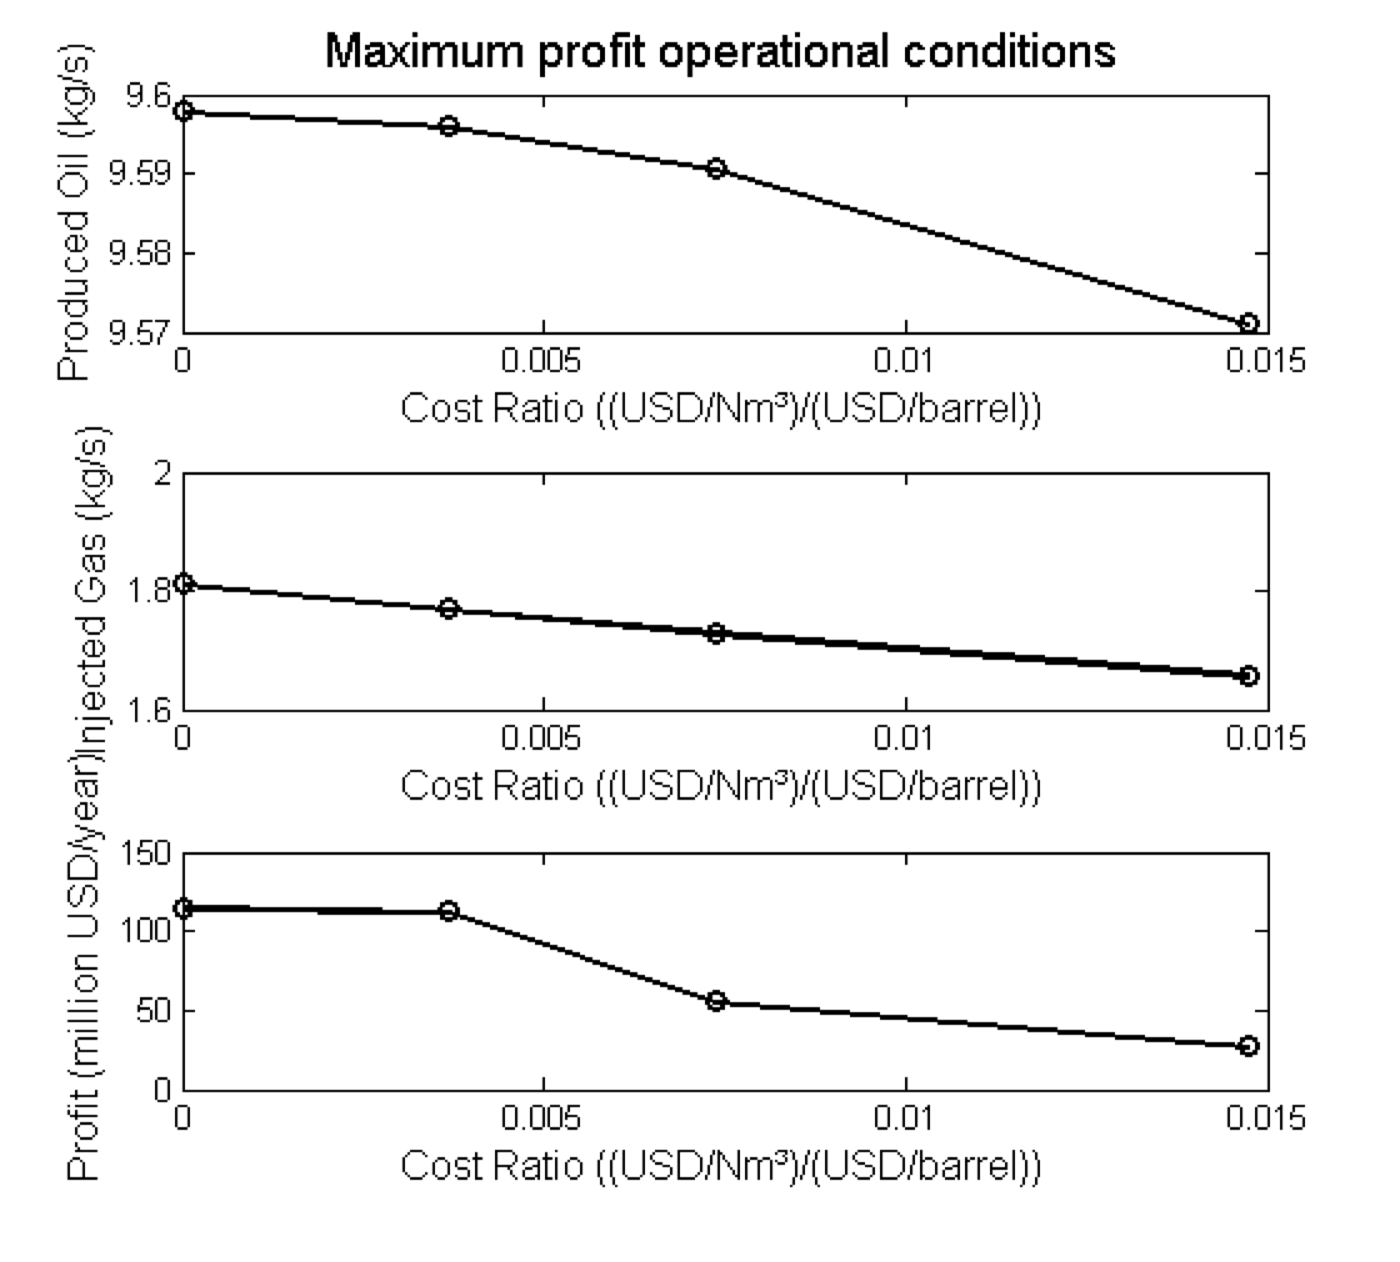

In [10]:
display(Image(filename=str(FIG / "FIG_16.png"), width=500))